In [ ]:
#!/bin/bash
!curl -L -o mobile-price-classification.zip https://www.kaggle.com/api/v1/datasets/download/iabhishekofficial/mobile-price-classification

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 72340  100 72340    0     0  73298      0 --:--:-- --:--:-- --:--:--  131k


In [ ]:
!unzip mobile-price-classification.zip

Archive:  mobile-price-classification.zip
  inflating: test.csv                
  inflating: train.csv               


In [ ]:
import pandas as pd
df=pd.read_csv('train.csv')
df

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,794,1,0.5,1,0,1,2,0.8,106,6,...,1222,1890,668,13,4,19,1,1,0,0
1996,1965,1,2.6,1,0,0,39,0.2,187,4,...,915,1965,2032,11,10,16,1,1,1,2
1997,1911,0,0.9,1,1,1,36,0.7,108,8,...,868,1632,3057,9,1,5,1,1,0,3
1998,1512,0,0.9,0,4,1,46,0.1,145,5,...,336,670,869,18,10,19,1,1,1,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [ ]:
df.isnull().sum()

,0
battery_power,0
blue,0
clock_speed,0
dual_sim,0
fc,0
four_g,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.nunique()

,0
battery_power,1094
blue,2
clock_speed,26
dual_sim,2
fc,20
four_g,2
int_memory,63
m_dep,10
mobile_wt,121
n_cores,8


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

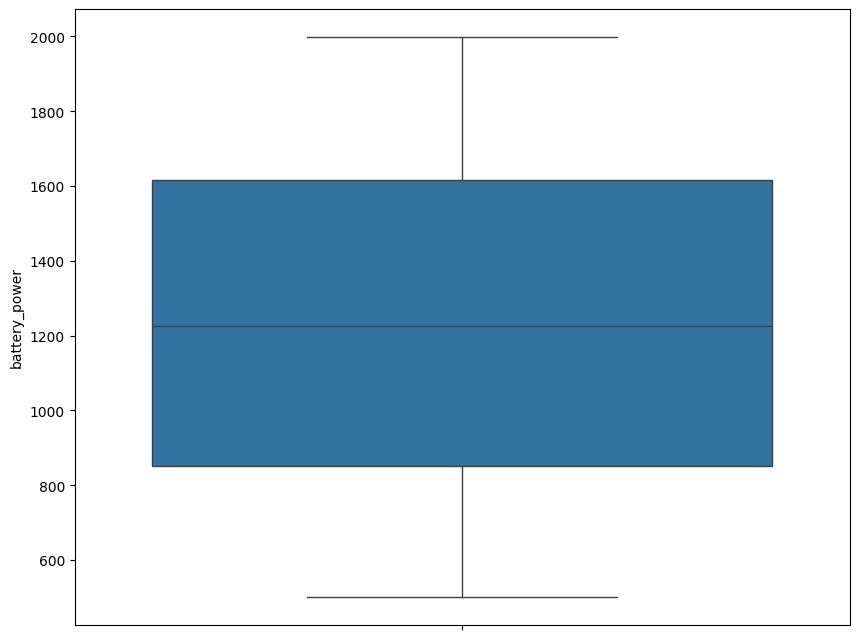

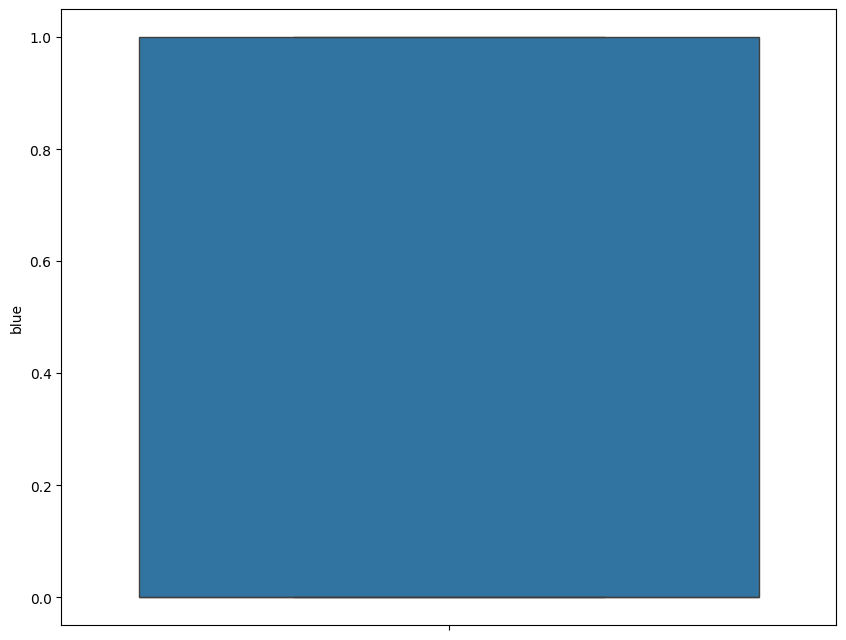

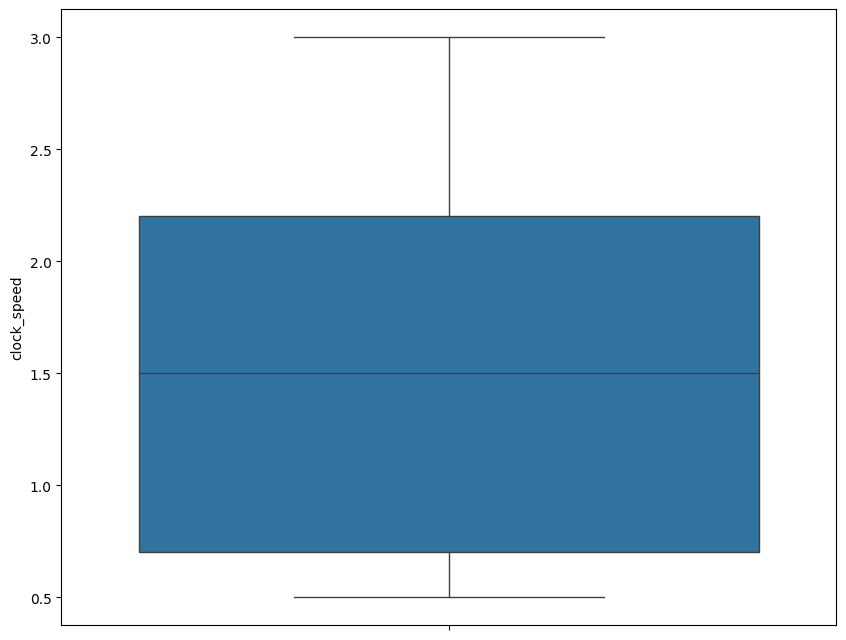

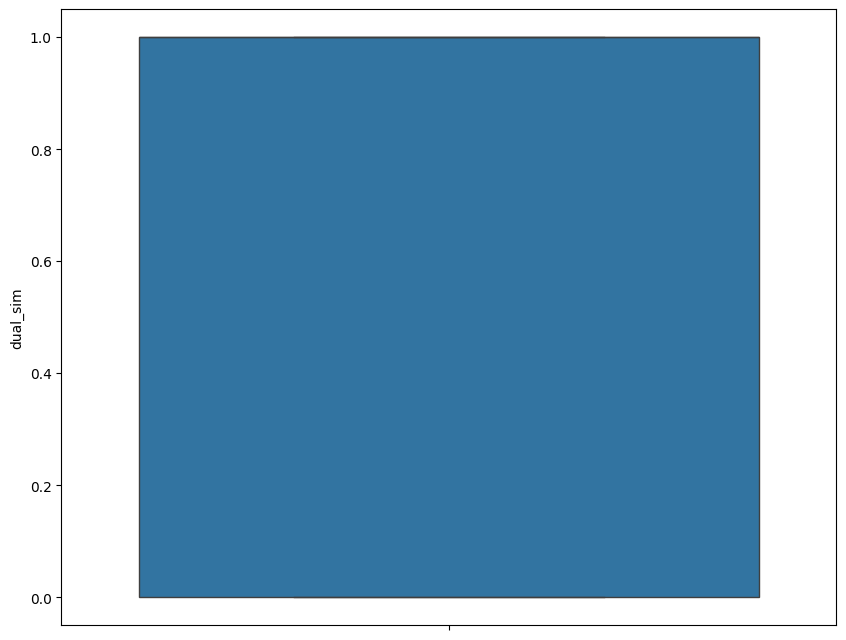

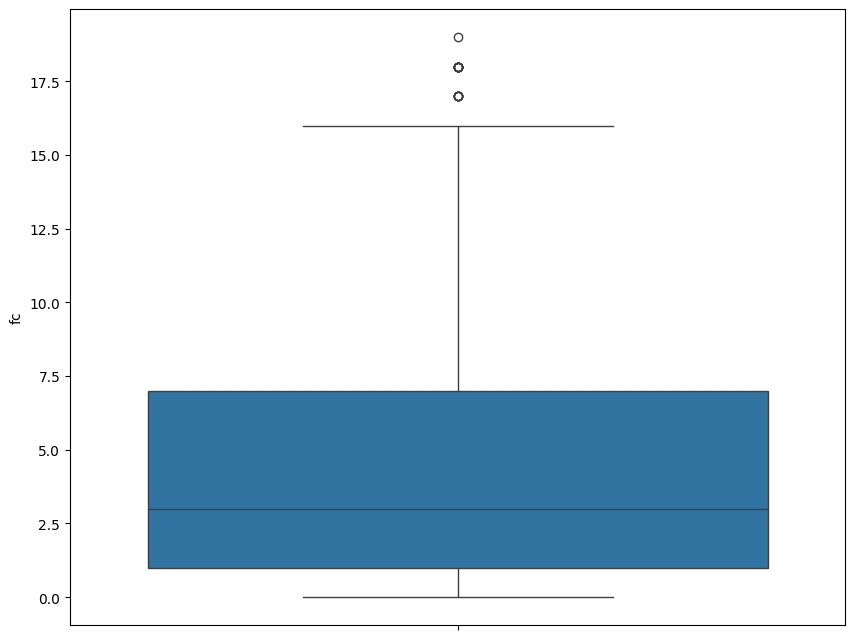

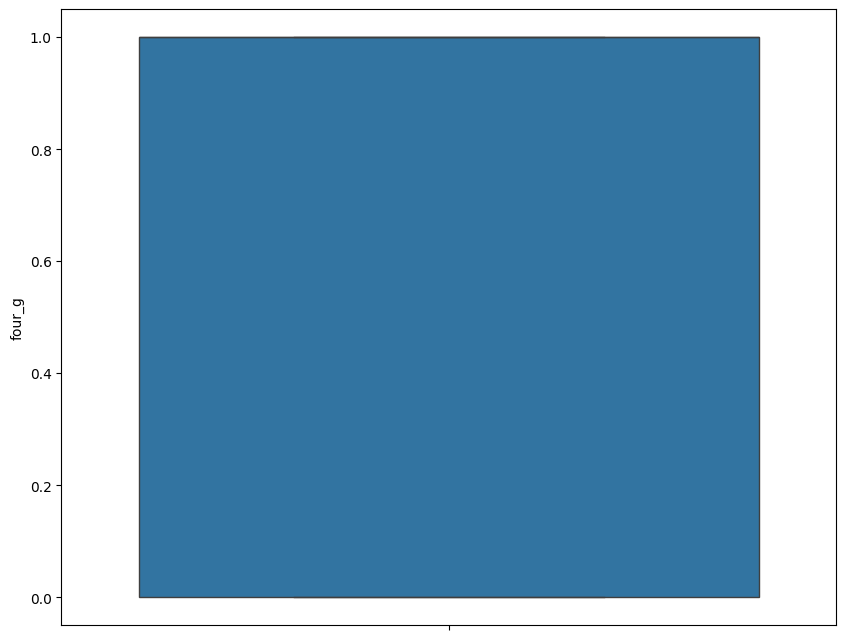

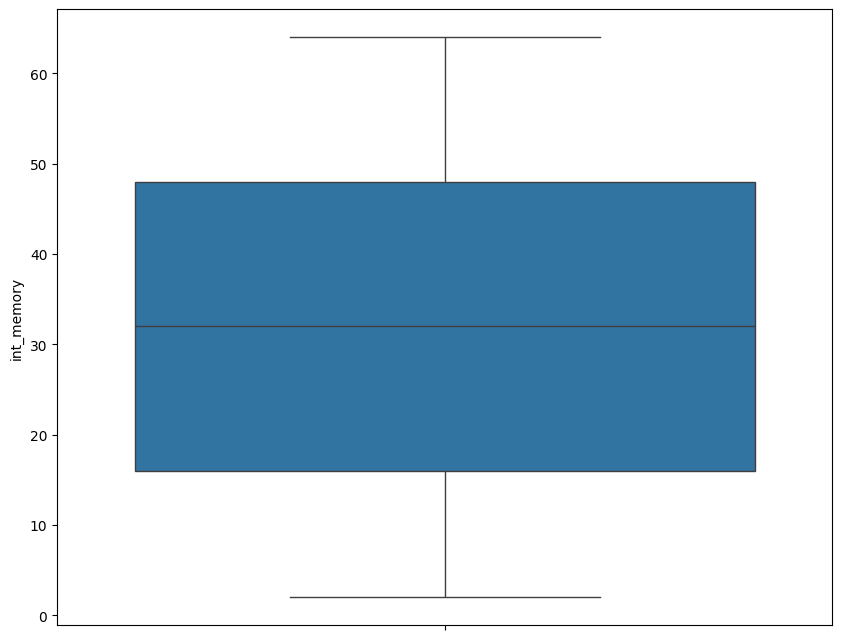

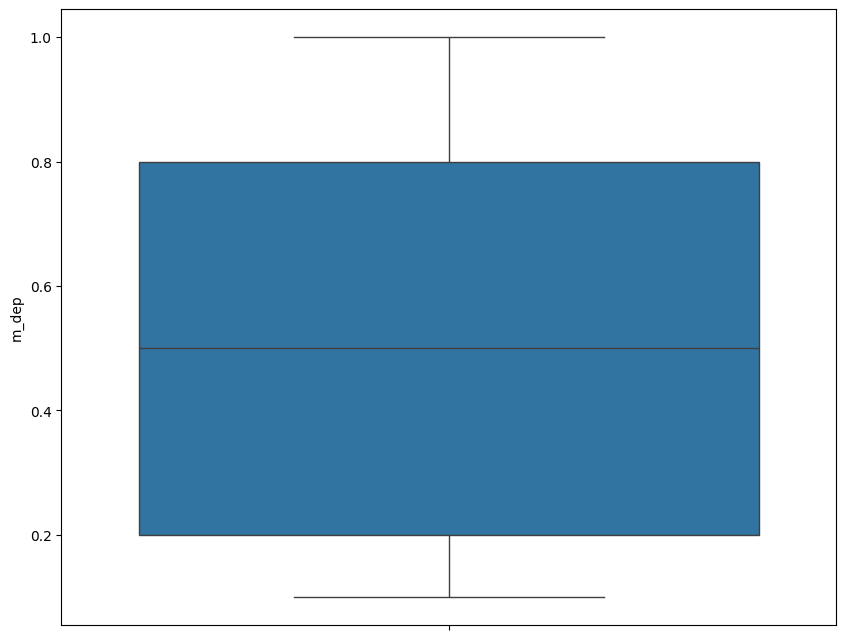

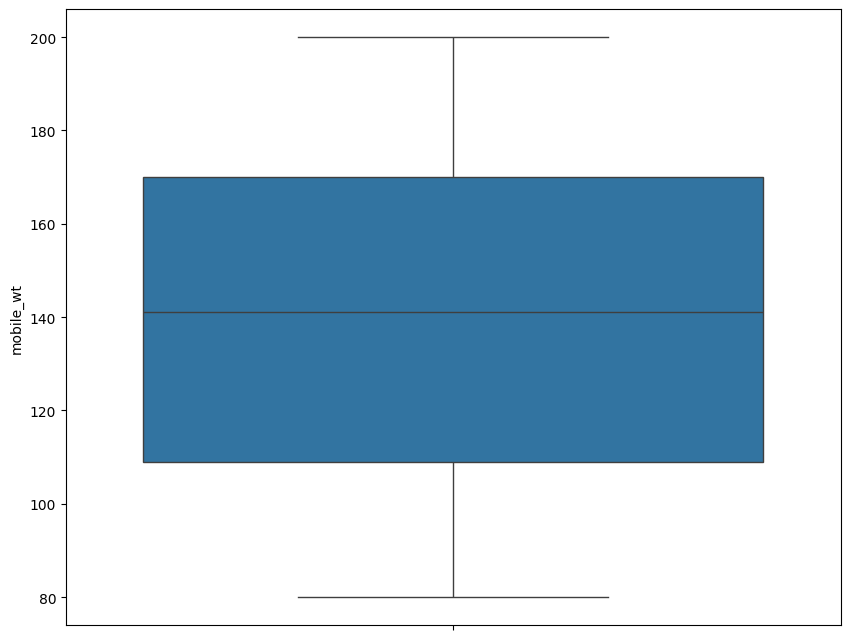

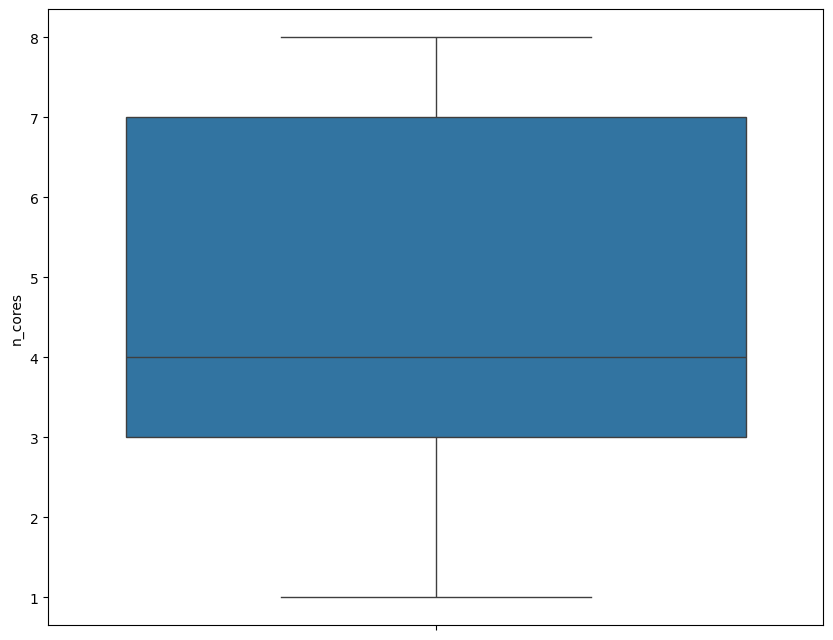

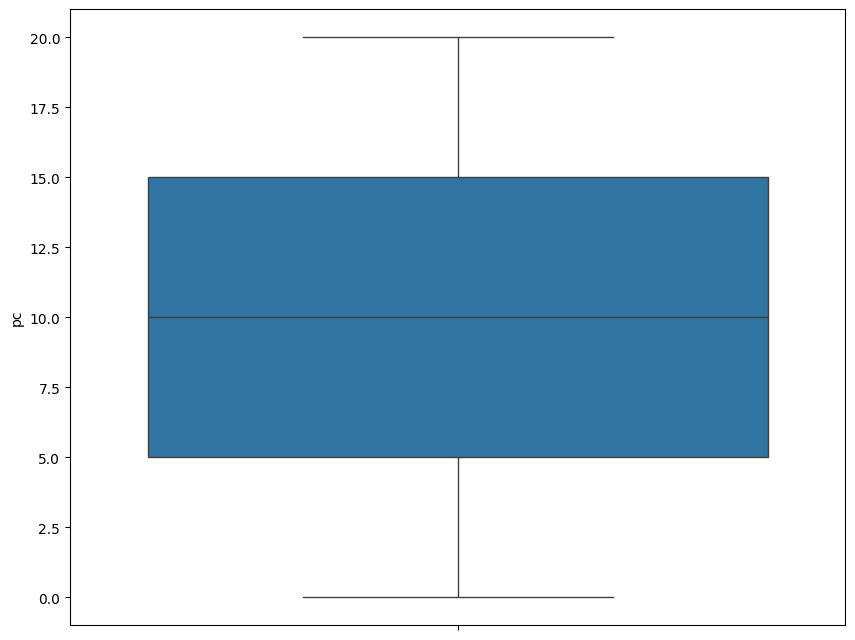

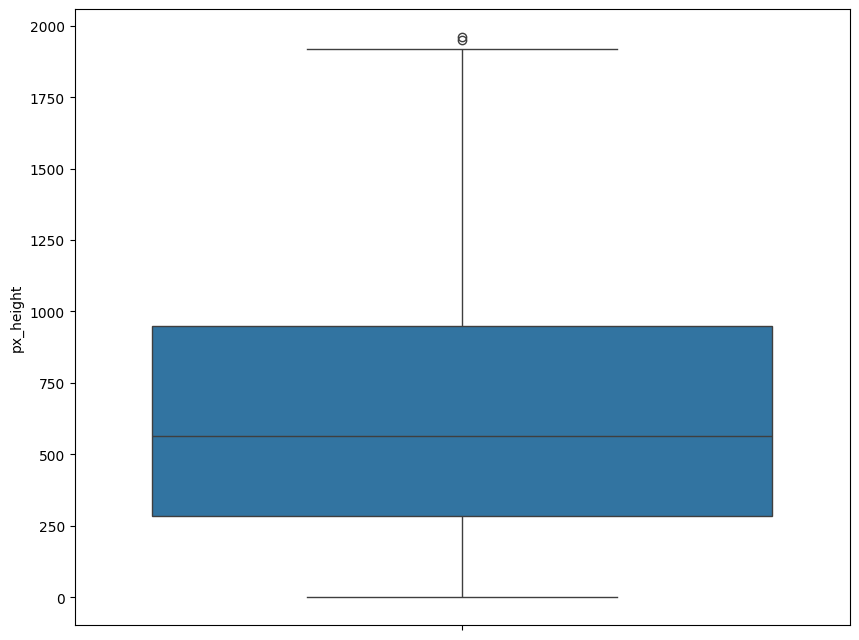

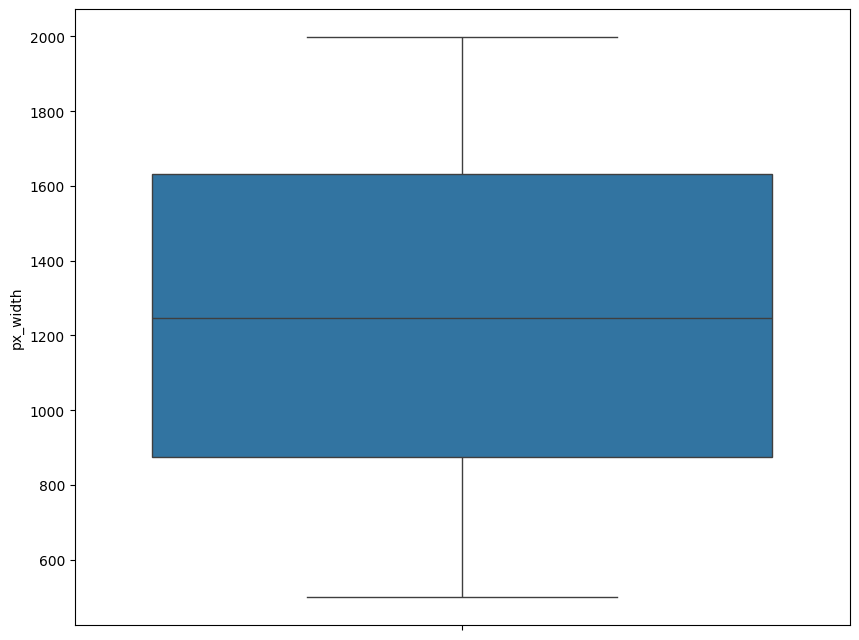

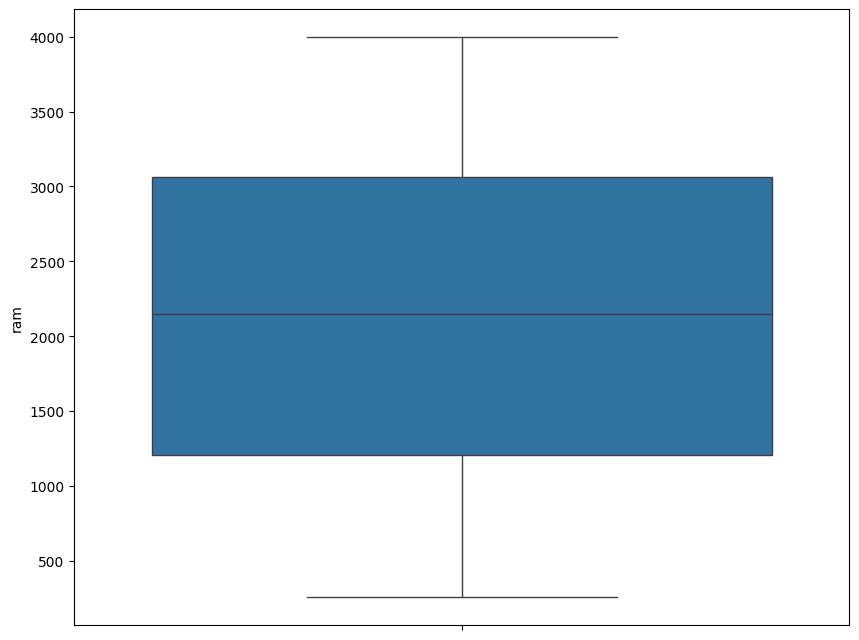

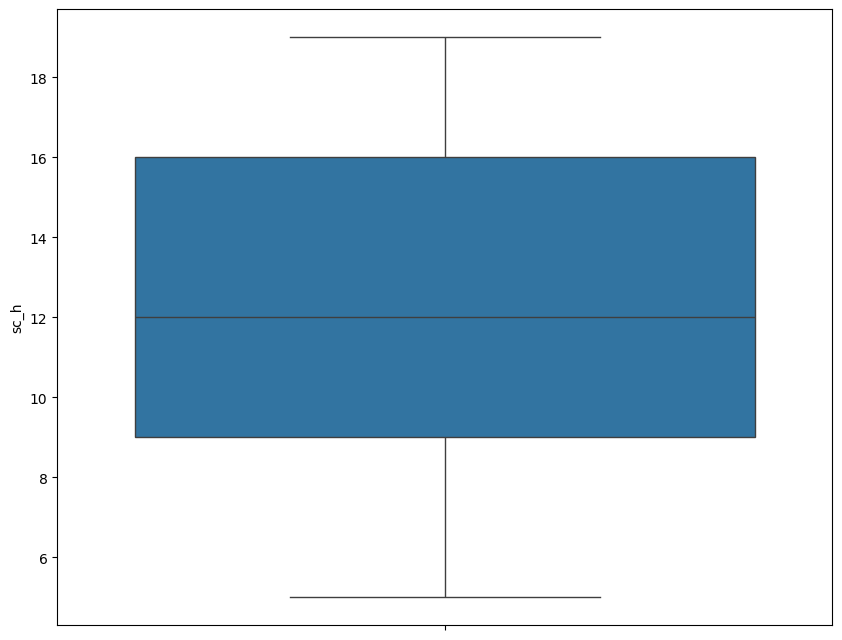

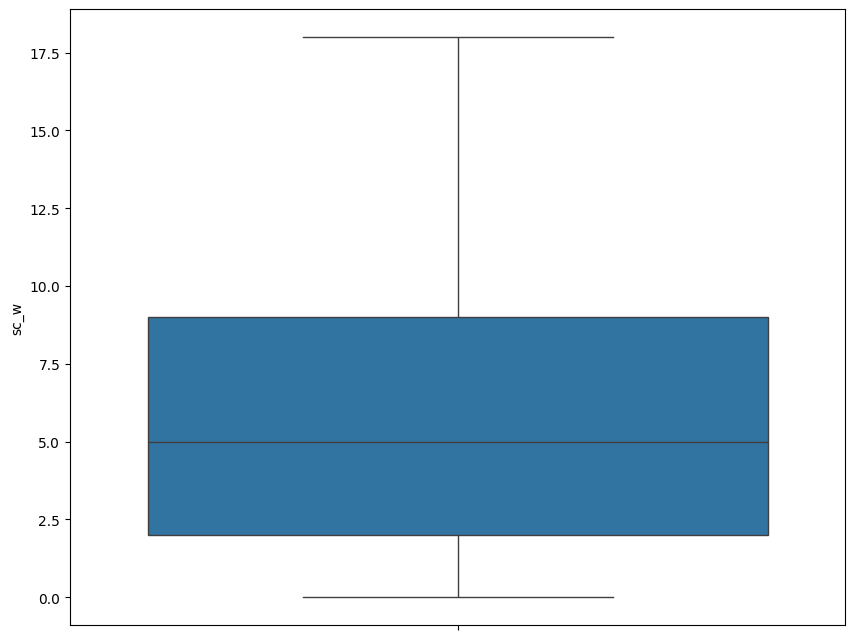

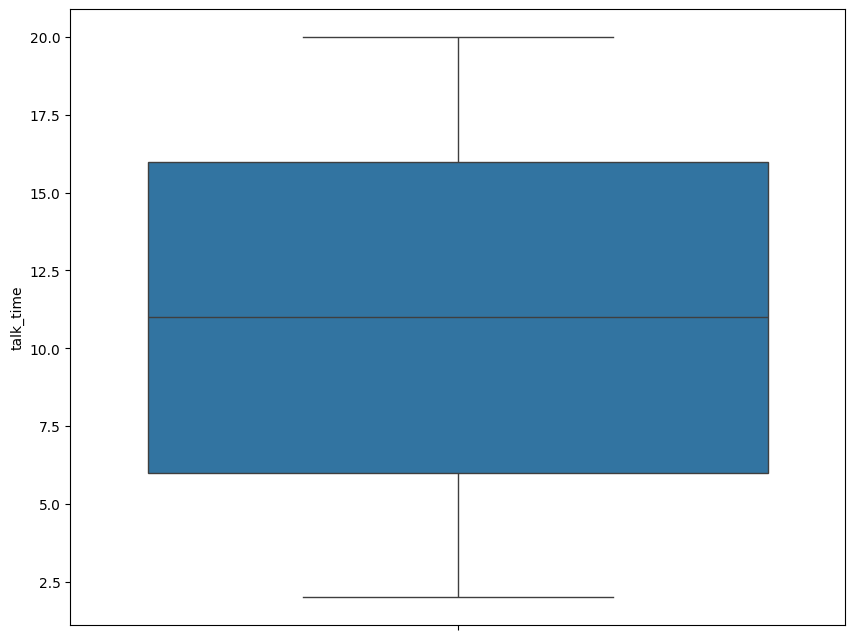

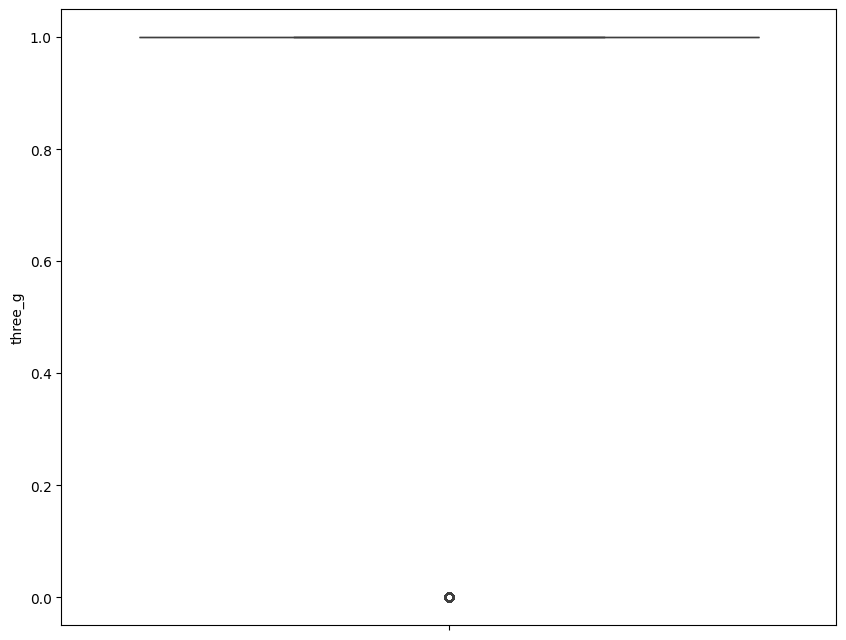

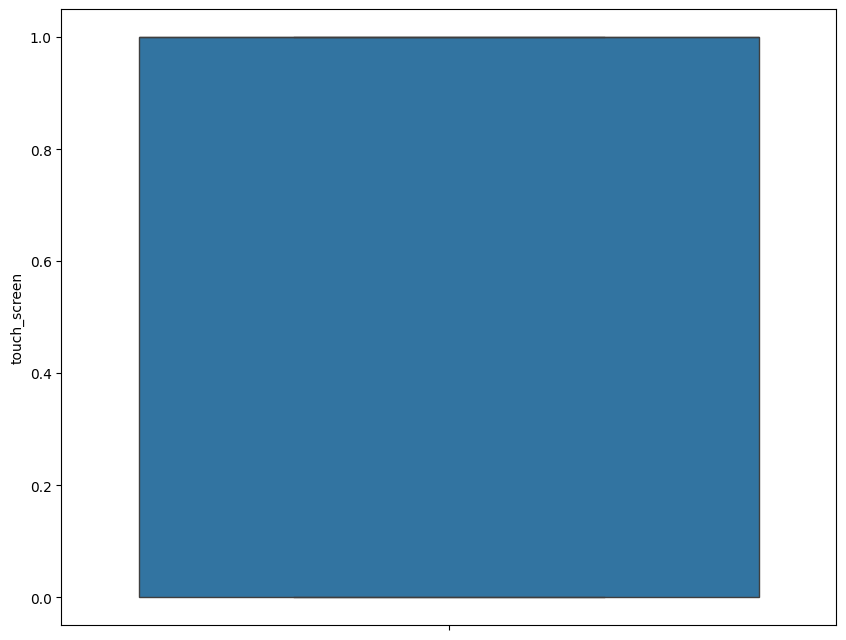

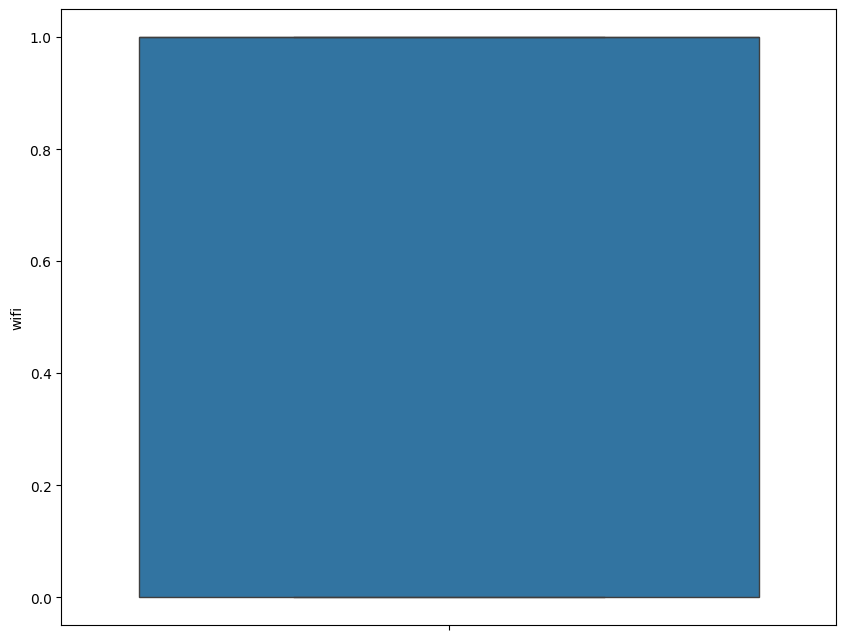

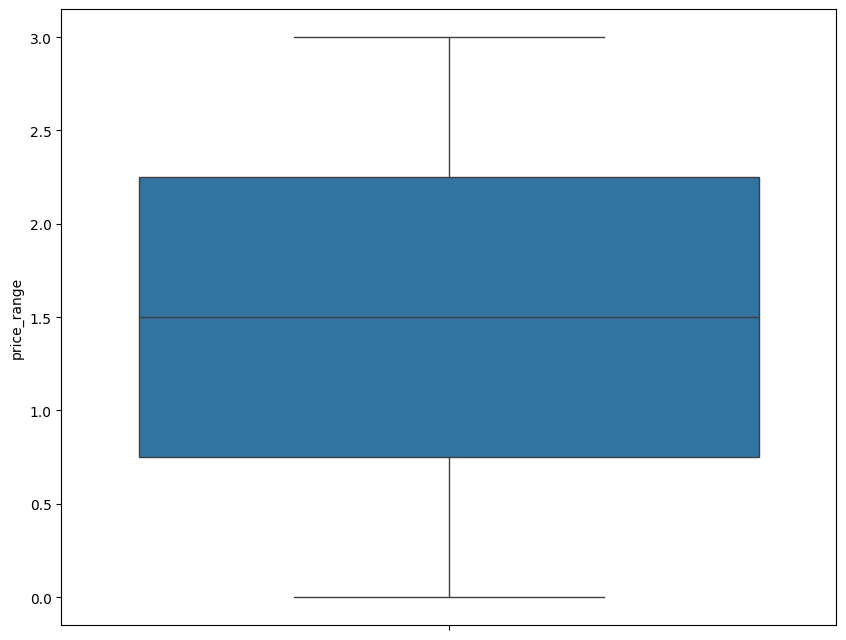

In [ ]:
for col in df.columns:
  plt.figure(figsize=(10,8))
  sns.boxplot(df[col])
  plt.show()

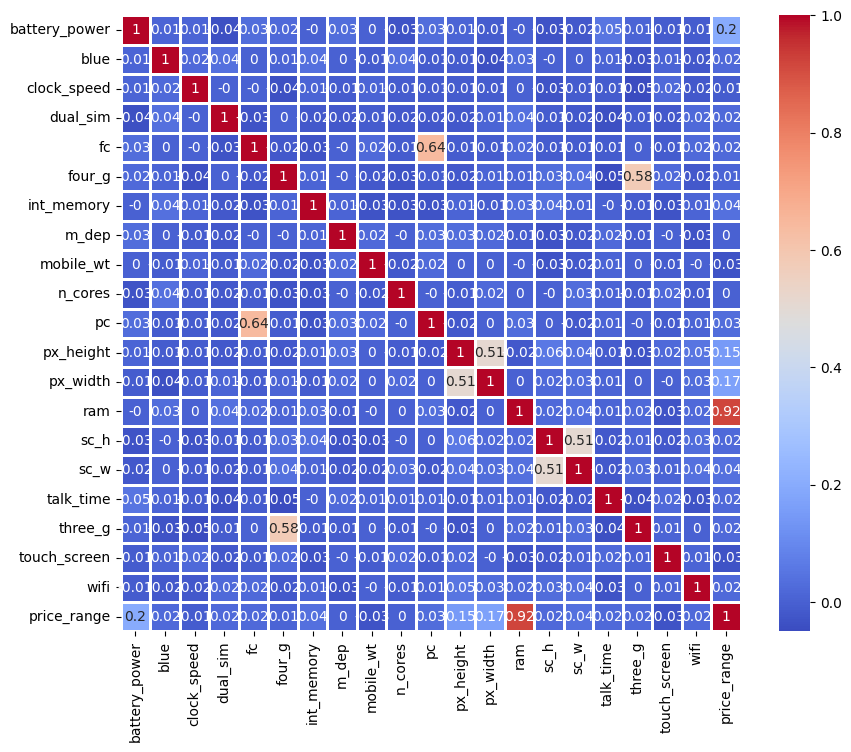

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr().round(2),annot=True,cmap='coolwarm',linewidths=1)
plt.show()

In [ ]:
df.drop('ram',axis=1,inplace=True)

In [ ]:
X=df.drop('price_range',axis=1)
y=df['price_range']

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [ ]:
pipeline=Pipeline([
    ('impute',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler())
])

In [ ]:
X_train=pipeline.fit_transform(X_train)
X_test=pipeline.transform(X_test)

In [ ]:
import torch
import numpy as np
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.long)
y_test = torch.tensor(y_test.values, dtype=torch.long)

In [ ]:
y_train.shape

torch.Size([1600])

In [ ]:
X_train.shape

torch.Size([1600, 19])

In [ ]:
from torch.utils.data import TensorDataset,DataLoader
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

In [ ]:
import torch.nn as nn

In [ ]:
class MobilePriceClassifier(nn.Module):
  def __init__(self,n_features,n_outputs=4):
    super().__init__()
    self.model=nn.Sequential(
        nn.Linear(n_features,64),
        nn.ReLU(),
        nn.Linear(64,32),
        nn.ReLU(),
        nn.Linear(32,n_outputs)
    )
  def forward(self,X):
    return self.model(X)


In [ ]:
n_classes = len(np.unique(np.array(y_train)))

In [ ]:
n_features=X_train.shape[1]

In [ ]:
model=MobilePriceClassifier(n_features=n_features,n_outputs=n_classes)

In [ ]:
optimizer=torch.optim.Adam(model.parameters(),lr=0.0001)
criterion=nn.CrossEntropyLoss()

In [ ]:
def train(model,optimizer,criterion,train_loader,n_epochs, device):
  model.train()
  model.to(device)
  for epoch in range(n_epochs):
    total_loss=0.
    for X_batch,y_batch in train_loader:
      X_batch,y_batch=X_batch.to(device) ,y_batch.to(device)
      y_pred=model(X_batch)
      loss=criterion(y_pred,y_batch)
      total_loss+=loss.item()
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
    mean_loss=total_loss/len(train_loader)
    print(f'epoch: {epoch+1}/{n_epochs},loss: {mean_loss}')

In [ ]:
if torch.cuda.is_available:
  device='cuda'
elif torch.backends.mps.is_available:
  device='mps'
else:
  device='cpu'

In [ ]:
train(model,optimizer,criterion,train_loader,20,device)

epoch: 1/20,loss: 0.916302568912506
epoch: 2/20,loss: 0.9126933014392853
epoch: 3/20,loss: 0.9108195352554321
epoch: 4/20,loss: 0.9096690762042999
epoch: 5/20,loss: 0.9080106163024902
epoch: 6/20,loss: 0.9068433845043182
epoch: 7/20,loss: 0.9061813735961914
epoch: 8/20,loss: 0.9051383316516877
epoch: 9/20,loss: 0.9040758514404297
epoch: 10/20,loss: 0.9030529081821441
epoch: 11/20,loss: 0.902235267162323
epoch: 12/20,loss: 0.9006680119037628
epoch: 13/20,loss: 0.8999434006214142
epoch: 14/20,loss: 0.8988635945320129
epoch: 15/20,loss: 0.8980251109600067
epoch: 16/20,loss: 0.896714961528778
epoch: 17/20,loss: 0.8956274437904358
epoch: 18/20,loss: 0.8949899208545685
epoch: 19/20,loss: 0.8940050530433655
epoch: 20/20,loss: 0.8928795301914215
